# Supplementary Fig. 6e: sorting accuracy of Buccino's model, the MEArec models and our biophysical model (Kilosort4)

**author**: laquitainesteeve@gmail.com

**purpose**: reproduce panel e of Supplementary Fig. 6: sorting accuracy, the proportion of ground truth neurons that are well detected (best agreement score with a sorted single-unit of at least 0.8, delta time 1.3 ms), for Buccino's model (2020), the MEArec models S2 to S5 and our biophysical model of the spontaneous regime (NS), sorted with Kilosort4 from the first 10 minutes. Source data and svg are saved in figures/8_source_data/supp_fig6e/.

**data**: as in supp_fig6d.ipynb; ground truth neurons that do not fire in the 10 minutes count as not detected (`src/nodes/analysis/accuracy/accuracy.py`).

**Prerequisites**: the simulations S2-S5 and their Kilosort4 sortings are produced as described in "Prerequisites" of `supp_fig6c.ipynb`.

In [1]:
# SETUP PACKAGES
import os
import warnings
import numpy as np
import pandas as pd
import spikeinterface as si
from matplotlib import pyplot as plt
warnings.simplefilter(action="ignore")

# SET PROJECT PATH
PROJ_PATH = "/home/steeve/steeve/epfl/code/spikebias"
os.chdir(PROJ_PATH)
from src.nodes.validation import firing_rate as fr
from src.nodes.analysis.accuracy import accuracy as acc

# datasets (first 10 minutes), sorted with Kilosort4
DATASETS = ["Buccino", "s2", "s3", "s4", "s5", "NS"]
SORTING_PATHS = {
    "Buccino": "dataset/01_intermediate/sorting/buccino/SortingKS4_10m",
    "s2": "dataset/01_intermediate/sorting/synth2/SortingKS4_10m",
    "s3": "dataset/01_intermediate/sorting/synth3/SortingKS4_10m",
    "s4": "dataset/01_intermediate/sorting/synth4/SortingKS4_10m",
    "s5": "dataset/01_intermediate/sorting/synth5/SortingKS4_10m",
    "NS": "dataset/01_intermediate/sorting/npx_spont/SortingKS4_10m",
}
GROUND_TRUTH_PATHS = {
    "Buccino": "dataset/00_raw/sorting_buccino",
    "s2": "dataset/00_raw/ground_truth_synth2",
    "s3": "dataset/00_raw/ground_truth_synth3",
    "s4": "dataset/00_raw/ground_truth_synth4",
    "s5": "dataset/00_raw/ground_truth_synth5",
    "NS": "dataset/00_raw/ground_truth_npx_spont",
}

# FIGURE SETTINGS
plt.rcParams["font.family"] = "DejaVu Sans"   # the paper's figure was drawn without Arial (matplotlib default font)
plt.rcParams["font.size"] = 6  # 5-7 with Nature neuroscience as reference
plt.rcParams["lines.linewidth"] = 0.5
plt.rcParams["axes.linewidth"] = 0.5
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False
plt.rcParams["xtick.major.width"] = 0.5
plt.rcParams["ytick.major.width"] = 0.5
plt.rcParams["xtick.major.size"] = 3.5 * 1.1
plt.rcParams["ytick.major.size"] = 3.5 * 1.1
savefig_cfg = {"transparent": True, "dpi": 300}

In [ ]:
# Nature figure guidelines for every saved figure: Arial, 5-7 pt, editable text, images of at least 300 dpi, a .pdf next to each .svg
import os, sys
sys.path.insert(0, os.getcwd())     # the repository (the notebook moved there above)
from src.nodes import figure_style
figure_style.apply()

## Sorting accuracy

In [2]:
%%time

DELTA_TIME = 1.3        # ms
THRESHOLD = 0.8
rows = []
for d in DATASETS:
    scores = acc.get_accuracy_for(SORTING_PATHS[d], GROUND_TRUTH_PATHS[d], DELTA_TIME)          # best agreement score of each ground truth neuron
    rows.append({"dataset": d, "n_ground_truth_units": len(scores), "n_well_detected_units": int((scores >= THRESHOLD).sum()), "accuracy": float((scores >= THRESHOLD).mean())})
df = pd.DataFrame(rows)
display(df)

,dataset,n_ground_truth_units,n_well_detected_units,accuracy
0,Buccino,250,224,0.896000
1,s2,1388,829,0.597262
2,s3,1388,402,0.289625
3,s4,1388,261,0.188040
4,s5,1388,194,0.139769
5,NS,1388,79,0.056916


CPU times: user 28.6 s, sys: 4 s, total: 32.6 s
Wall time: 32.7 s


## Plot, same as the paper's panel e

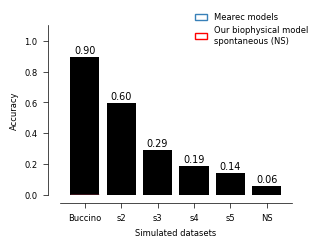

In [3]:
def plot_source_data(df: pd.DataFrame):
    """Sorting accuracy of each simulated dataset"""
    from src.nodes.validation import supp_fig6_layout as lay

    fig = lay.new_figure(lay.DE_CANVAS)
    ax = lay.add_axes_pt(fig, *lay.E_AXES)
    ax.bar(df["dataset"], df["accuracy"], color="k", width=0.8)
    for i, v in enumerate(df["accuracy"]):
        ax.text(i, v + 0.01, f"{v:.2f}", ha="center", va="bottom", fontsize=7)
    ax.set_ylim(0, 1.1)
    ax.set_yticks(np.arange(0, 1.1, 0.2), [f"{v:.1f}" for v in np.arange(0, 1.1, 0.2)])
    ax.set_ylabel("Accuracy")
    ax.set_xlabel("Simulated datasets")
    ax.spines["bottom"].set_position(("axes", -0.05))
    ax.yaxis.set_ticks_position("left")
    ax.spines["left"].set_position(("axes", -0.05))
    # legend of the paper
    from matplotlib.patches import Patch
    handles = [Patch(facecolor="none", edgecolor=(0.22, 0.5, 0.72), label="Mearec models"), Patch(facecolor="none", edgecolor="r", label="Our biophysical model\nspontaneous (NS)")]       # no bar is drawn for the legend
    ax.legend(handles=handles, frameon=False, loc="upper left", bbox_to_anchor=(0.55, 1.12), fontsize=6, handlelength=1.5)
    lay.set_text_sizes(fig)
    return fig, ax


fig, ax = plot_source_data(df)

## Save the figure and the source data

In [4]:
os.makedirs("figures/8_source_data/supp_fig6e", exist_ok=True)
fig.savefig("figures/8_source_data/supp_fig6e/supp_fig6e.svg", bbox_inches="tight", **savefig_cfg)
df.to_excel("figures/8_source_data/supp_fig6e/supp_fig6e.xlsx", index=False)

## Check: replot from the saved source data

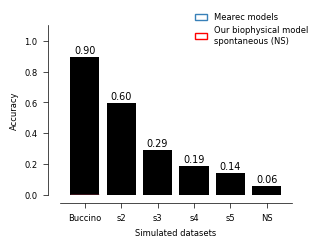

In [5]:
df_loaded = pd.read_excel("figures/8_source_data/supp_fig6e/supp_fig6e.xlsx")
fig, ax = plot_source_data(df_loaded)